# TP 4: Information Retrieval Models

```(Scoring, Term Weighting and the Vector Space Model)```

## Problem Set:

- Learn how to create and interpret a Term Document Matrix (TDM) for a set of documents. And apply the Vector Space Model to calculate document similarity using cosine similarity.

## Problem 1: Create a Term Document Matrix

### Task: Create a Term Document Matrix for a small set of documents.

### Instructions:

#### 1. Choose the following three sample documents:
- Document 1: ```Data science combines statistics, computer science, and domain knowledge.```

- Document 2: ```Machine learning algorithms can analyze large datasets and make predictions.```

- Document 3: ```Data visualization helps in interpreting complex data and communicating insights.```


In [29]:
DOCS = [
    "Data science combines statistics, computer science, and domain knowledge.",
    "Machine learning algorithms can analyze large datasets and make predictions.",
    "Data visualization helps in interpreting complex data and communicating insights."
]

#### 2. Write a function to tokenize each document (split into words) and count the frequency of each term.


In [30]:
import re  # Load the tool for finding words using a text rule.
from collections import Counter  # Load the tool for counting repeated items.

def tokenize1(text): # Make a function that takes one document and return tokenize and freq count
    text = text.lower()
    words = re.findall(r"[a-z]+", text)
    counts = Counter(words)
    return counts

# apply the function
term_counts = []
for doc_id, doc in enumerate(DOCS, start=1):
    counts = tokenize1(doc)
    term_counts.append(counts)
    print("Document", doc_id, ":", dict(counts))

Document 1 : {'data': 1, 'science': 2, 'combines': 1, 'statistics': 1, 'computer': 1, 'and': 1, 'domain': 1, 'knowledge': 1}
Document 2 : {'machine': 1, 'learning': 1, 'algorithms': 1, 'can': 1, 'analyze': 1, 'large': 1, 'datasets': 1, 'and': 1, 'make': 1, 'predictions': 1}
Document 3 : {'data': 2, 'visualization': 1, 'helps': 1, 'in': 1, 'interpreting': 1, 'complex': 1, 'and': 1, 'communicating': 1, 'insights': 1}


#### 3. Construct the Term Document Matrix (TDM) and print it.

In [31]:
# Collect all different words, then sort them in letter order.
word_set = set()
for counts in term_counts:
    word_set.update(counts.keys())
vocab = sorted(word_set)

# Build one row of word counts for each document.
TDM = []
for counts in term_counts:
    row = []
    for term in vocab:
        row.append(counts[term]) # Counter gives 0 if the word is absent
    TDM.append(row)

# Print the column names, followed by each document's row.
print("Terms:", vocab)
for doc_id, row in enumerate(TDM, start=1):
    print("Document", doc_id, ":", row)



Terms: ['algorithms', 'analyze', 'and', 'can', 'combines', 'communicating', 'complex', 'computer', 'data', 'datasets', 'domain', 'helps', 'in', 'insights', 'interpreting', 'knowledge', 'large', 'learning', 'machine', 'make', 'predictions', 'science', 'statistics', 'visualization']
Document 1 : [0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 2, 1, 0]
Document 2 : [1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0]
Document 3 : [0, 0, 1, 0, 0, 1, 1, 0, 2, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1]


## Problem 2: Visualize the Term Document Matrix
### Task: Display the Term Document Matrix in a readable format.
### Instructions:
#### 1. Using the TDM created in Problem 1, format the matrix into a table.


In [32]:
import pandas as pd
table = pd.DataFrame(TDM, columns=vocab)
table

,algorithms,analyze,and,can,combines,communicating,complex,computer,data,datasets,...,interpreting,knowledge,large,learning,machine,make,predictions,science,statistics,visualization
0,0,0,1,0,1,0,0,1,1,0,...,0,1,0,0,0,0,0,2,1,0
1,1,1,1,1,0,0,0,0,0,1,...,0,0,1,1,1,1,1,0,0,0
2,0,0,1,0,0,1,1,0,2,0,...,1,0,0,0,0,0,0,0,0,1


#### 2. Ensure that the rows represent documents and the columns represent terms.

In [34]:
# Show the labels used for rows and columns.
print("Rows (documents):", table.index.tolist())
print("Columns (words):", table.columns.tolist())

# Show how many rows and columns the table has.
print("Number of rows:", table.shape[0])
print("Number of columns:", table.shape[1])

Rows (documents): [0, 1, 2]
Columns (words): ['algorithms', 'analyze', 'and', 'can', 'combines', 'communicating', 'complex', 'computer', 'data', 'datasets', 'domain', 'helps', 'in', 'insights', 'interpreting', 'knowledge', 'large', 'learning', 'machine', 'make', 'predictions', 'science', 'statistics', 'visualization']
Number of rows: 3
Number of columns: 24


#### 3. Print the TDM with appropriate labels for documents and terms.

In [36]:
# rename the row
table.index = ["doc1", "doc2", "doc3"]

# Show every word column when displaying this table.
with pd.option_context("display.max_columns", None):
    display(table)

,algorithms,analyze,and,can,combines,communicating,complex,computer,data,datasets,domain,helps,in,insights,interpreting,knowledge,large,learning,machine,make,predictions,science,statistics,visualization
doc1,0,0,1,0,1,0,0,1,1,0,1,0,0,0,0,1,0,0,0,0,0,2,1,0
doc2,1,1,1,1,0,0,0,0,0,1,0,0,0,0,0,0,1,1,1,1,1,0,0,0
doc3,0,0,1,0,0,1,1,0,2,0,0,1,1,1,1,0,0,0,0,0,0,0,0,1


## Problem 3: Implement TF-IDF
### Task: Calculate TF-IDF weights for the terms in the TDM.
### Instructions:
#### 1. Using the TDM from Problem 1, write a function to calculate the TF-IDF for each term in each document (Lecture 4, N = 3):
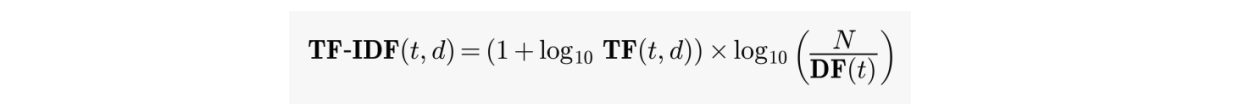

#### Personal Notation:

The task gives this formula:

```TF-IDF = (1 + log₁₀(TF)) × log₁₀(N / DF)```

- TF: how many times the word appears in the current document.
- DF: how many documents contain the word.
- N: total number of documents—here, 3.

If a word is absent, its weight is 0. We handle that separately because log₁₀(0) cannot be calculated.

In [38]:
import math 
def calculate_tfidf(count_table):
    N = len(count_table) # count doc rows

    # Make a separate table that can hold decimal weights.
    weights = count_table.astype(float).copy()

    for term in count_table.columns:
        # count the doc were this word appears.
        df  = (count_table[term]>0).sum()
        idf = math.log10(N / df)

        for doc in count_table.index:
            tf = count_table.loc[doc, term] # read this word's count in this doc
            if tf == 0:
                weights.loc[doc, term] = 0
            else :
                weights.loc[doc, term] = (
                    (1+math.log10(tf)) * idf 
                )
    return weights

# Apply the function to our word-count table.
tfidf_table = calculate_tfidf(table)
tfidf_table

,algorithms,analyze,and,can,combines,communicating,complex,computer,data,datasets,...,interpreting,knowledge,large,learning,machine,make,predictions,science,statistics,visualization
doc1,0.000000,0.000000,0.0,0.000000,0.477121,0.000000,0.000000,0.477121,0.176091,0.000000,...,0.000000,0.477121,0.000000,0.000000,0.000000,0.000000,0.000000,0.620749,0.477121,0.000000
doc2,0.477121,0.477121,0.0,0.477121,0.000000,0.000000,0.000000,0.000000,0.000000,0.477121,...,0.000000,0.000000,0.477121,0.477121,0.477121,0.477121,0.477121,0.000000,0.000000,0.000000
doc3,0.000000,0.000000,0.0,0.000000,0.000000,0.477121,0.477121,0.000000,0.229100,0.000000,...,0.477121,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.477121


#### 2. Display the TF-IDF matrix.

In [39]:
# Show all word columns, with weights rounded to three decimal places.
with pd.option_context("display.max_columns", None):
    display(tfidf_table.round(3))


,algorithms,analyze,and,can,combines,communicating,complex,computer,data,datasets,domain,helps,in,insights,interpreting,knowledge,large,learning,machine,make,predictions,science,statistics,visualization
doc1,0.000,0.000,0.0,0.000,0.477,0.000,0.000,0.477,0.176,0.000,0.477,0.000,0.000,0.000,0.000,0.477,0.000,0.000,0.000,0.000,0.000,0.621,0.477,0.000
doc2,0.477,0.477,0.0,0.477,0.000,0.000,0.000,0.000,0.000,0.477,0.000,0.000,0.000,0.000,0.000,0.000,0.477,0.477,0.477,0.477,0.477,0.000,0.000,0.000
doc3,0.000,0.000,0.0,0.000,0.000,0.477,0.477,0.000,0.229,0.000,0.000,0.477,0.477,0.477,0.477,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.477
